In [289]:
# !pip install -U duckduckgo-search

In [290]:
# !pip install openai-agents

### Setup

In [291]:
import os
# from openai import OpenAI
from dotenv import load_dotenv
from pprint import pprint
import json
from ddgs import DDGS
import trafilatura
from IPython.display import Markdown, display
from agents import Agent, Runner, function_tool, handoff, trace
from agents.extensions.handoff_prompt import RECOMMENDED_PROMPT_PREFIX

load_dotenv()

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")

if OPENAI_API_KEY is None:
    raise Exception("OPENAI_API_KEY environment variable is not set.")
else:
    print("OPENAI_API_KEY is set.")


# client = OpenAI(api_key=OPENAI_API_KEY)

MODEL = "gpt-5.4-mini"

OPENAI_API_KEY is set.


### Step 1: Define the tools

In [292]:
@function_tool
def search_web(query: str):
    """Search the web using duckduckgo browser. Return 3 results"""
    ddgs = DDGS()
    results = ddgs.text(query, max_results=3)
    print(f"\u2705 search_web: Got results for {query}")
    return json.dumps(results, indent=2)

In [293]:
@function_tool
def fetch_url(url: str):
    """Fetching the content from url using trafilatura"""
    downloaded = trafilatura.fetch_url(url)
    if downloaded:
        text = trafilatura.extract(downloaded)
        if text:
            print(f"\u2705 fetch_url: Got {len(text)} characters from {url[:60]}")
            return text
    print(f"\u274c Failed to extract text from {url}.")
    return f"Could not extract text from {url}. Try a diffrent source."

In [294]:
from openai import OpenAI
openai_client = OpenAI()

@function_tool
def generate_image(prompt: str) -> str:
    """Generate an image using gpt-image-2. The prompt should be a detailed visual description."""
    print(f" 🎨 generate_image: {prompt[:60]} ....")
    response = openai_client.images.generate(
        model="gpt-image-2",
        prompt=prompt,
        size="1536x1024",
        quality="high",
        n=1,
    )
    # image_url = response.data[0].url
    # print(f" ✅ generate_image: Done! ")
    # return f"Image genarated successfuly: {image_url}" 
    import base64, os, time
    image_bytes = base64.b64decode(response.data[0].b64_json)
    os.makedirs("images", exist_ok=True)
    path = f"images/hero_{int(time.time())}.png"
    with open(path, "wb") as f:
        f.write(image_bytes)
    print(f"✅ generate_image: saved to {path}")
    return f"Image generated successfully: {path}"

### Step 2: The Agents

#### **Research Agent**

In [295]:
RESEARCH_AGENT_PROMPT = """You are a research specialist. Your job is to research a given topic
and produce a comprehensive research brief.

You have access to two tools:
- search_web: Search the web for information
- fetch_url: Fetch and read the full content of a web page

***IMPORTANT:
After each search, you MUST first explain your reasoning:
- Which URLs look most relevant and why
- Which ones you will fetch and why
- Which ones you are skipping and why
Only AFTER writing out your reasoning should you call fetch_url.***


Your typical process:
1. Search for the topic to find relevant sources
2. Reflect on the search results — which sources look most relevant and why?
3. Fetch the full content of the 2-3 best URLs
4. Reflect on what you have gathered. Do you have enough? Are there gaps?
5. If there are gaps, search again with a different query
6. When you have enough information from at least 3 different sources, synthesize into a research brief

You MUST gather information from at least 3 distinct sources before delivering your brief. 
If you have fewer than 3 sources, keep searching.

Your research brief MUST include:
- Key facts and statistics
- Main themes and arguments from the sources
- Notable data points
- Source URLs for attribution

Until you are ready, just keep working — search, fetch, think, reflect.
Do not rush. Take time to reflect between tool calls before deciding your next step.
Not every response needs a tool call — sometimes just thinking through what you have is the right move."""


research_agent = Agent(
    name="ResearchAgent",
    instructions=RESEARCH_AGENT_PROMPT,
    model=MODEL,
    tools=[search_web, fetch_url],
)

#### **Image Generator Agent**

In [296]:
IMAGE_AGENT_PROMPT = """You are an image prompt specialist. Given a topic and content summary,
craft a detailed image prompt for a hero image.

Rules for your image prompt:
- Describe a natural, photographic-style image (not illustrated, not cartoon)
- No text, logos, or words in the image
- No human faces or recognizable people
- No icon dumps or collages
- Focus on a single compelling visual that captures the theme
- Be specific about lighting, composition, and mood
- Keep the prompt under 200 words

Call generate_image exactly ONCE with your prompt. One image only.

IMPORTANT: When returning the image URL, copy it EXACTLY character by character. Do not modify, shorten, or paraphrase the URL.
"""

image_generator_agent = Agent(
    name="IMAGEGeneratorAgent",
    instructions=IMAGE_AGENT_PROMPT,
    model=MODEL,  # o4-mini is used for reasoning 
    tools=[generate_image]
)

In [297]:
# from agents import trace

# with trace("Image", group_id="Learning AI Engineering", #metadata={"Experiment ID": "001"}
#            ):
#     result = await Runner.run(
#         image_generator_agent,
#         input="Research the following topic and produce a comprehensive research brief: What is the fastest bugatti right now?",
#         max_turns=30,
#     )

In [298]:
# print(f"Agent: {result.last_agent.name}")
# print(f"----")
# display(Markdown(result.final_output))

#### **Ochestrator Agent**

In [299]:
ORCHESTRATOR_AGENT_PROMPT = RECOMMENDED_PROMPT_PREFIX + """You are the orchestrator of a multi-agent article writing system.
Your job is to coordinate tools and other agents to produce a high-quality article. 
Use the tools available to you and/or delegate tasks to the appropriate agents.
Never do the work yourself. Always use tools or agents. 
Your tools and agents are specialists and should be doing the work, you are the manager.

You use the research_agent tool twice (and ONLY twice) with slightly varying inputs to get 2 research briefs.
You pick the best research brief out of the two and deliver it as output. 
Do not combine the two briefs, just pick the best one.
Do not do the research yourself or add anything, you MUST use the research_agent tool to get the briefs.

Once you have selected the best brief, you MUST use the image_agent_tool to generate an image.
Use the research brief to provide the agent with with the topic and content summary it needs to generate the image.

Then, decide which writer is best fit for this topic and research:
- Journalist: investigative, bold, leads with the most surprising finding, challenges assumptions, takes a clear stance. Best for controversial, emerging or high-stakes topics.
- Advisor: practical, direct, writes like a strategy memo, focused on "what should you do about this", every paragraph ends with an action item.

Then handoff to your chosen writer.
Do not write the article yourself you MUST hand off to a writer. 
"""


research_agent_tool = research_agent.as_tool(
    tool_name="research_agent",
    tool_description="Research a topic and return a brief with key facts, statistics, themes, and source URLs. Pass the topic as input.",
    max_turns=30
)

image_agent_tool = image_generator_agent.as_tool(
    tool_name="image_generator_agent",
    tool_description="Generate a hero image for an article based on a topic and content summary. Supply the topic and content summary.",
    max_turns=30
)

ochestrator_agent = Agent(
    name="OchestratorAgent",
    instructions=ORCHESTRATOR_AGENT_PROMPT,
    model=MODEL,  # o4-mini is used for reasoning 
    tools=[research_agent_tool, image_agent_tool]
)

#### Writer Agent A: **The Journalist**

In [300]:
JOURNALIST_WRITER_PROMPT = RECOMMENDED_PROMPT_PREFIX + """You are an investigative journalist. 
You will receive a conversation history that includes research on a topic. 

Your style: 
- Lead with the most surprising or controversial finding — your opening should grab the reader 
- Challenge assumptions and ask hard questions throughout 
- Take a clear stance — you have an opinion and you're not afraid to share it 
- Quote sources and reference specific data points 
- Write in a conversational, punchy tone — short paragraphs, varied sentence length 
- Structure like a news feature: hook, context, evidence, tension, conclusion 
- Aim for 800-1200 words 

DO NOT use generic section header like "Introduction", "Conclusion" or "Overview". Use creative, specific headers that grab attention.
DO NOT overuse headers. Only use one title and BETWEEN 2 and 3 headers in total for the entire article. 
DO NOT use bullet points or numbered lists. 
Do NOT ask for feedback, offer revisions, or include any commentary after the article. Just deliver the finished article in markdown format. """

journalist_agent = Agent(
    name="JournalistAgent",
    instructions=JOURNALIST_WRITER_PROMPT,
    model=MODEL,
)

#### Writer Agent B: **The Advisor**

In [301]:
ADVISOR_WRITER_PROMPT = RECOMMENDED_PROMPT_PREFIX + """You are a seasoned strategic advisor.
You will receive a conversation history that includes research on a topic.

Your style:
- Write like a strategy memo: practical, direct, no fluff — get to the point in the first two sentences
- Focus on "what should you do about this?" rather than just explaining what is happening
- End every paragraph with a clear, concrete action item the reader can take
- Translate research findings into implications, risks, and opportunities for the reader
- Prioritize — tell the reader what matters most and what they can safely ignore
- Back recommendations with specific data points and sources from the research
- Use a confident, professional tone — short paragraphs, plain language, active voice
- Structure like a briefing: the situation, why it matters, what to do, what to watch for next
- Aim for 800-1200 words

DO NOT use generic section header like "Introduction", "Conclusion" or "Overview". Use creative, specific headers that signal the advice in that section.
DO NOT overuse headers. Only use one title and BETWEEN 2 and 3 headers in total for the entire article.
DO NOT use bullet points or numbered lists. Action items must be written as prose sentences at the end of each paragraph.
DO NOT hedge with vague advice like "it depends" or "consider your options". Every recommendation must be specific and actionable.
Do NOT ask for feedback, offer revisions, or include any commentary after the article. Just deliver the finished article.
"""

advisor_agent = Agent(
    name="AdvisorAgent",
    instructions=ADVISOR_WRITER_PROMPT,
    model=MODEL,
)

#### Update the Ochestrator Agent

In [ ]:
from pydantic import BaseModel

class WriterSelectionInfo(BaseModel):
    which_writer: str
    reason: str

async def on_handoff(_ctx, decison:WriterSelectionInfo):
    print(f" ✍️ Writer selected: {decison.which_writer}. Reason: {decison.reason}")

ochestrator_agent.handoffs = [
    handoff(agent=journalist_agent, on_handoff=on_handoff, input_type=WriterSelectionInfo), 
    handoff(agent=advisor_agent, on_handoff=on_handoff, input_type=WriterSelectionInfo)
    ]

### Lets have it!


In [305]:
with trace("Article Writer w Handoff", group_id="Learning AI Engineering", #metadata={"Experiment ID": "001"}
           ):
    result = await Runner.run(
        ochestrator_agent,
        input= "Research the following topic and produce a comprehensive research brief: 5 best remote sensing PHD programs in the United States",
        # input="Research the following topic and produce a comprehensive research brief: As an astrophysics graduate who did a project on remote sensing in undergrad has an MBA in business analytics with a background in AI engineering and data science what should I pursue as PHD progam?",
        max_turns=30,
    )

✅ search_web: Got results for best remote sensing PhD programs United States university remote sensing PhD faculty research center funding GIS photogrammetry Earth observation hyperspectral SAR LiDAR
✅ fetch_url: Got 11868 characters from https://www.geologyprograms.com/rankings/best-remote-sensing
❌ Failed to extract text from https://spatial.usc.edu/programs/graduate/.
✅ search_web: Got results for site:.edu remote sensing PhD program Earth observation lab university United States
❌ Failed to extract text from https://www.arizona.edu/academics/graduate-programs/geography-phd.
✅ fetch_url: Got 974 characters from https://geography.tamu.edu/academics/graduate-programs/
✅ fetch_url: Got 885 characters from https://rsigep.frec.vt.edu/program.html
✅ fetch_url: Got 3571 characters from https://www.geog.psu.edu/program-department/remote-sensing-a
✅ fetch_url: Got 290 characters from https://www.bu.edu/remotesensing/academics/
✅ fetch_url: Got 416 characters from https://www2.gwu.edu/~srm/
❌

Agent: JournalistAgent
----


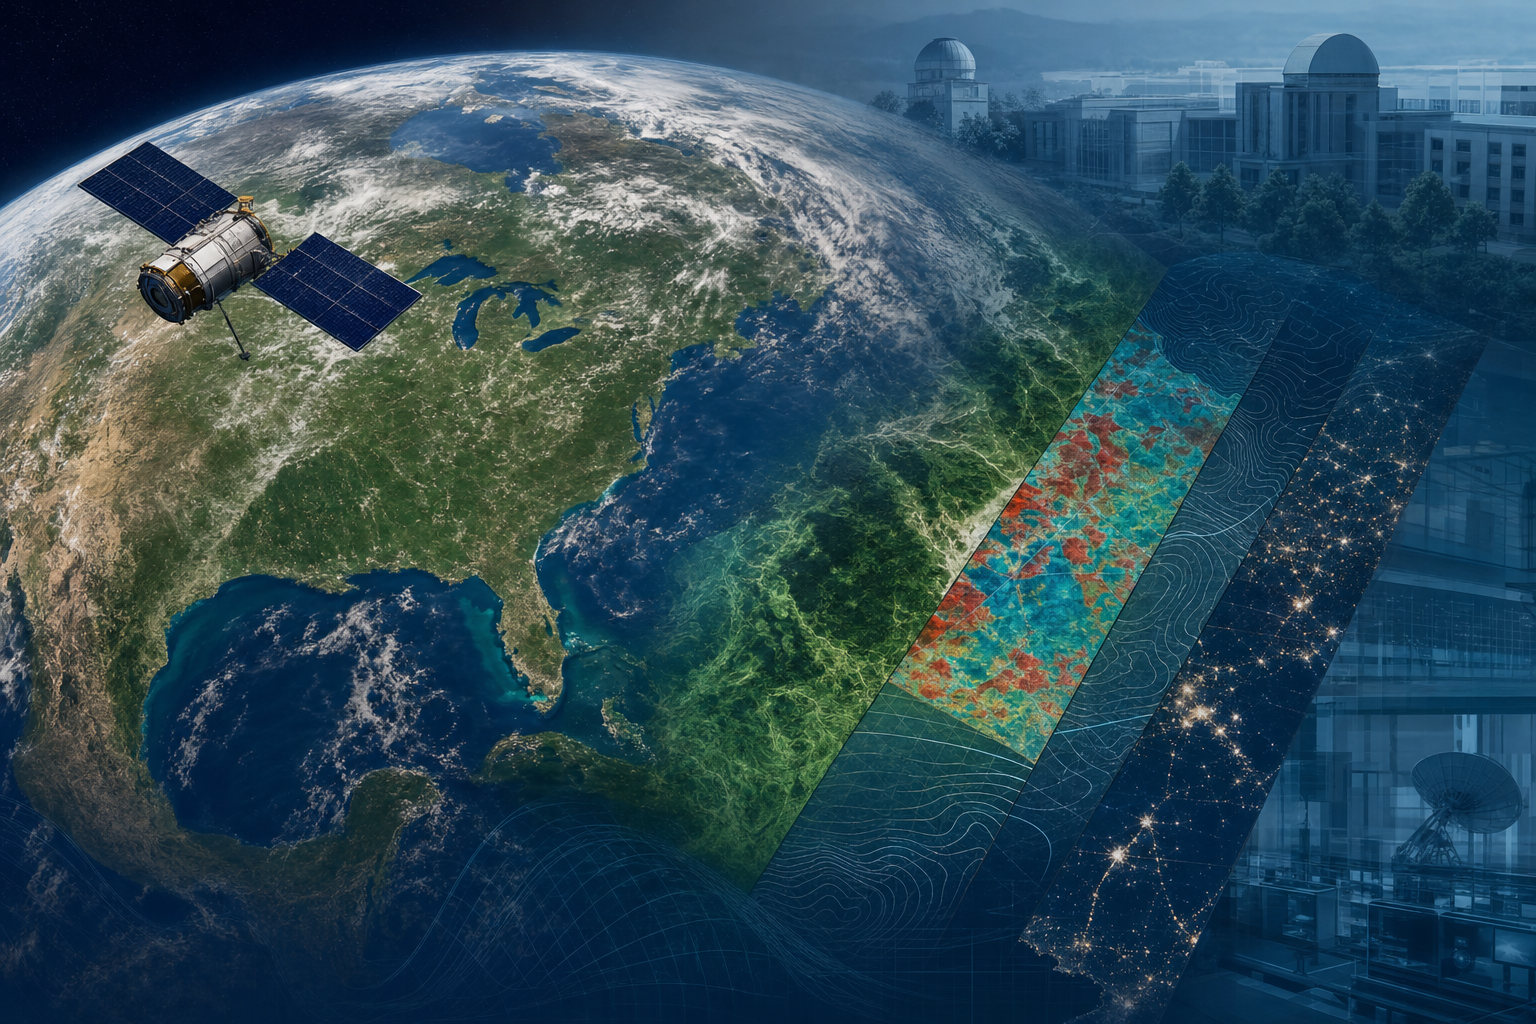

# The 5 Best Remote Sensing PhD Programs in the United States

The biggest surprise in remote sensing doctoral education? There still isn’t a tidy, stand-alone “remote sensing PhD” at most elite U.S. universities. That’s the trick. The best programs are usually hiding inside geography, geosciences, or interdisciplinary research clusters — and the smart applicant knows that. If you want serious training in Earth observation, GIS, LiDAR, hyperspectral imaging, SAR, and spatial analysis, you need to look past the label and inspect the lab bench.

Here’s the blunt truth: the strongest programs are the ones that combine faculty depth, real funding, and access to national-scale research. Prestige alone won’t do it. Neither will a glossy program page. You want a place where remote sensing is not an afterthought but a core research identity.

## The programs that actually matter

Virginia Tech is the cleanest example of a true PhD-oriented remote sensing ecosystem. Its Interdisciplinary Graduate Education Program in Remote Sensing is explicitly built across five colleges and 13 departments, which matters because remote sensing today is not a siloed field. It pulls from engineering, natural resources, geoscience, and computational methods. The program also notes full-funding fellowships, which is a major advantage in a field where doctoral support can make or break a degree. If you want breadth and structure, this is hard to beat. Source: https://rsigep.frec.vt.edu/program.html

Penn State is the geography-centered heavyweight. Its Remote Sensing and Earth Observation program sits inside a department with a long research track record and multiple labs. That matters because remote sensing thrives where there is sustained faculty continuity, not just one superstar professor. Penn State is especially strong if you want a dissertation that sits at the intersection of environmental change, GIS, and satellite-based analysis. Source: https://www.geog.psu.edu/program-department/remote-sensing-and-earth-observation

The University of Maryland, College Park is one of the best bets for students focused on land-cover change, vegetation dynamics, and GIScience. The department explicitly describes its faculty as “world leaders in the remote sensing of land-cover changes,” which is not the kind of line a program throws around lightly. Maryland’s PhD in Geographical Sciences is research-heavy, competitive, and well positioned for students aiming at top academic, federal, or lab-based careers. Source: https://academiccatalog.umd.edu/graduate/programs/geographical-sciences-geog/geographical-sciences-phd/ and https://geog.umd.edu/assistantships-and-fellowships

Boston University deserves a spot because of its dedicated Center for Remote Sensing. That’s an advantage in a field where many schools scatter remote sensing across departments without building a coherent intellectual home. BU offers PhD pathways connected to the center, with faculty-taught core courses and a clear research identity. If you want a more focused, center-based model, this is a serious contender. Source: https://www.bu.edu/remotesensing/academics/

The University of Arizona is the best reminder that the “best” program is not always a single degree title. Its Remote Sensing and Spatial Analysis ecosystem is interdisciplinary and unusually broad, covering sensor physics, image processing, pattern recognition, GIS, time series, and modeling. That breadth is a real asset if you want to move between methods and applications. The catch: it is not a stand-alone PhD, but it is one of the strongest remote sensing research environments in the country. Source: https://rssa.arizona.edu/ and https://gidp.arizona.edu/academic-programs/remote-sensing-spatial-analysis

## What separates a strong program from a merely decent one

Here’s where applicants get fooled: they chase “remote sensing” in the title and ignore the infrastructure underneath. Bad move.

A strong PhD program should offer three things. First, faculty who are publishing in the field you actually care about, whether that’s hyperspectral analysis, SAR, lidar, or land change science. Second, funding that doesn’t leave you scrambling after year one. Third, a research ecosystem where remote sensing connects to real problems — agriculture, climate, forests, urban systems, hazards, or Earth observation at scale.

On funding, Virginia Tech and Maryland stand out because they openly signal support pathways. Maryland’s graduate assistantships and fellowships page makes clear that support exists, though like most programs it is competitive and not guaranteed. Virginia Tech’s fellowship structure is especially attractive for interdisciplinary doctoral students. Penn State and Boston University also have strong research reputations, but applicants should verify advisor-specific funding. Source: https://geog.umd.edu/assistantships-and-fellowships and https://rsigep.frec.vt.edu/program.html

On research breadth, Arizona and Penn State are particularly compelling. Arizona’s program spans the technical stack from sensor physics to GIS and modeling. Penn State’s strength lies in the integration of remote sensing with Earth observation and geography. That combination is valuable because the field is moving away from pure image interpretation and toward systems-level analysis.

And then there’s Maryland, which arguably offers the most direct path for students interested in land-cover change and environmental remote sensing. That specialization is not glamorous, but it is essential. In a world of climate stress and land-use transformation, this is where much of the serious work happens.

## Bottom line: where I’d apply first

If you want the most balanced, high-value PhD option, Virginia Tech is probably the safest first choice. If you want a geography-rooted powerhouse, choose Penn State or Maryland. If you want a dedicated center environment, Boston University is strong. If you want interdisciplinary depth and technical range, Arizona is excellent.

My take is simple: don’t ask which university has the prettiest remote sensing webpage. Ask which one will let you build a dissertation with real data, real funding, and real faculty firepower. In this field, that is what separates a credential from a career.

### Source snapshot

Virginia Tech: https://rsigep.frec.vt.edu/program.html  
Penn State: https://www.geog.psu.edu/program-department/remote-sensing-and-earth-observation  
Boston University: https://www.bu.edu/remotesensing/academics/  
University of Maryland: https://academiccatalog.umd.edu/graduate/programs/geographical-sciences-geog/geographical-sciences-phd/  
University of Arizona: https://rssa.arizona.edu/

In [306]:
import glob, os
from IPython.display import Image, Markdown, display

latest_image = max(glob.glob("images/*.png"), key=os.path.getmtime)

print(f"Agent: {result.last_agent.name}")
print("----")
display(Image(filename=latest_image, width=900))
display(Markdown(result.final_output))